# Multi-Agent Financial Analysis and Investment Research System
**AAI-520 | Team 7 | Team members: Amit Vishwakarma and Rajkumar T**  
**Data source:** Yahoo Finance via `yfinance`  
**GitHub repository:** `https://github.com/vishwakarmaamit1/aai-520-nlp_and_gen_ai_final_project`

This notebook demonstrates planning, dynamic tool use, specialist routing, news prompt chaining, report synthesis, evaluator–optimizer iteration, and persistent memory. The evaluator now validates structured evidence; the optimizer performs a bounded news retry and reevaluates; and memory informs later planning. It is an educational prototype, not financial advice.

## 1. Agent Design and Workflows — Requirements and Architecture

| Rubric requirement | Implementation | Evidence in this notebook |
|---|---|---|
| Plan research steps | `PlannerAgent` + `PlanAndExecuteAgent` | Explicit plan phase, sequential execution phase, memory-informed recovery tasks |
| Use tools dynamically | `ToolRegistry` + orchestrator | Named tool calls, status logging, recovery attempts |
| Self-reflect | `EvaluatorAgent` | Structured checks against report and research data |
| Learn across runs | JSON-backed `MemoryAgent` | Prior feedback influences later plans; outcomes saved |
| Prompt chaining | `NewsAgent` | Ingest → Preprocess → Classify → Extract → Summarize, with stage counts |
| Routing | `RouterAgent` | Routes market, financial, and news tasks to specialists |
| Evaluator–optimizer | `evaluate_optimize` + `OptimizerAgent` | Evaluate → corrective action/retry → regenerate → reevaluate |

The notebook uses deterministic Python agents and rule-based news sentiment. It does not claim autonomous LLM reasoning or model-weight training. External data availability can vary between runs.

### Detailed design rationale

The system separates the research task into small responsibilities so each component has a clear input and output. The Planner describes the work to perform; the Plan-and-Execute Agent separates planning from execution; the Tool Registry provides controlled access to data functions; the Router selects a specialist; and the Synthesis Agent combines results into one report. This modular design makes it easier to test a component independently and to identify which stage failed.

**Information flow**
1. The user supplies a ticker symbol and analysis period.
2. The Planner validates the ticker and creates a research plan.
3. The Plan-and-Execute Agent freezes the plan, then executes each step in sequence and records its outcome.
4. The Router sends each task to the Market, Financial, or News specialist.
5. The specialists produce structured results.
6. The Synthesis Agent prepares a readable report.
7. The Evaluator checks report completeness and the Optimizer adds feedback when needed.
8. The Memory Agent stores a brief record for future runs.

**Design boundary:** This implementation uses Python rules and programmatic orchestration. It demonstrates the requested agent functions and workflow patterns, but it does not use an LLM to autonomously reason or generate every action. This distinction should be stated clearly in the submission.

**Plan-and-Execute distinction:** the planner proposes the task sequence first; the executor then follows that sequence and records outcomes. Evaluation and optimization happen after execution, so corrective actions remain visible rather than being hidden inside the initial plan.


## 2. Import dependencies

In [1]:
import json, re
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.max_columns", 30)
MEMORY_PATH = Path("research_memory.json")
SYMBOL = "NVDA"  # Change to AAPL, MSFT, GOOGL, TCS.NS, etc.
PERIOD = "1y"
print("Ready:", SYMBOL)

Ready: NVDA


## 3. Tool layer — Yahoo Finance
The registry enables agents to invoke data tools by name. Data retrieval errors are recorded instead of inventing values.

In [2]:
class YahooFinanceTools:
    def history(self, symbol, period="1y"):
        data = yf.Ticker(symbol).history(period=period, auto_adjust=False)
        if data is None or data.empty:
            raise ValueError(f"No price history returned for {symbol}")
        return data

    def company_info(self, symbol):
        try:
            return yf.Ticker(symbol).info or {}
        except Exception as exc:
            return {"_error": str(exc)}

    def statements(self, symbol):
        ticker = yf.Ticker(symbol)
        output = {}
        for key, attr in [("income_statement", "income_stmt"),
                          ("balance_sheet", "balance_sheet"), ("cash_flow", "cashflow")]:
            try:
                output[key] = getattr(ticker, attr)
            except Exception:
                output[key] = pd.DataFrame()
        return output

    def news(self, symbol):
        try:
            return yf.Ticker(symbol).news or []
        except Exception as exc:
            return [{"_error": str(exc)}]


class ToolRegistry:
    def __init__(self, source):
        self.tools = {"history": source.history, "company_info": source.company_info,
                      "statements": source.statements, "news": source.news}

    def call(self, name, **kwargs):
        if name not in self.tools:
            raise KeyError(f"Unregistered tool: {name}")
        print(f"[Tool] {name}")
        return self.tools[name](**kwargs)


tools = ToolRegistry(YahooFinanceTools())
print("Registered:", list(tools.tools))

Registered: ['history', 'company_info', 'statements', 'news']


## 4. Agent Functions and Capabilities — Planner Agent
The planner creates a stock-specific research plan before execution.

### Planner Agent — detailed explanation

The Planner converts the ticker and prior experience into a sequence of research tasks. Each task identifies a specialist, tool, and purpose. If prior memory shows that news retrieval returned no usable articles or a tool failed, the planner adds an explicit recovery task. The orchestrator logs every task outcome so the plan can be audited.

**Why it matters:** this demonstrates bounded, explainable adaptation based on experience. The plan is still rule-based; it is not presented as unrestricted autonomous reasoning.

In [3]:
class PlannerAgent:
    """Create a baseline plan and add a recovery task when prior memory suggests it."""
    def plan(self, symbol, prior_memory=None):
        symbol = symbol.strip().upper()
        if not re.fullmatch(r"[A-Z0-9.^=_-]{1,20}", symbol):
            raise ValueError("Invalid ticker symbol")
        plan = [
            {"step": 1, "specialist": "market", "tool": "history", "purpose": "Analyze historical price and returns"},
            {"step": 2, "specialist": "financial", "tool": "company_info", "purpose": "Retrieve company profile and key metrics"},
            {"step": 3, "specialist": "financial", "tool": "statements", "purpose": "Check financial statements"},
            {"step": 4, "specialist": "news", "tool": "news", "purpose": "Process recent news headlines"},
        ]
        # Cross-run adaptation: previous news gaps trigger a planned second retrieval attempt.
        prior_memory = prior_memory or []
        if prior_memory and (prior_memory[-1].get("news_count", 0) == 0 or prior_memory[-1].get("tool_error_count", 0) > 0):
            plan.append({"step": 5, "specialist": "news", "tool": "news", 
                         "purpose": "Recovery retrieval informed by a previous news gap or tool error"})
        return plan

planner = PlannerAgent()
pd.DataFrame(planner.plan(SYMBOL))

,step,specialist,tool,purpose
0,1,market,history,Analyze historical price and returns
1,2,financial,company_info,Retrieve company profile and key metrics
2,3,financial,statements,Check financial statements
3,4,news,news,Process recent news headlines


## 5. Specialist agents — market and financial analysis

### Specialist responsibilities and expected outputs

**Market Agent**
- Calculates the latest and first closing prices in the retrieved period.
- Calculates period return from those two observations.
- Estimates annualized historical volatility from daily percentage returns.
- Calculates 20- and 50-observation moving averages when enough observations exist.
- Retains the underlying price history for visualization.

**Financial Agent**
- Selects available company profile and financial metric fields from the returned company information.
- Checks whether income statement, balance sheet, and cash-flow data are available.
- Reports availability instead of assuming that every company provides every field.

**News Agent**
- Converts available news records into a consistent structure.
- Applies transparent keyword rules to classify topic and sentiment.
- Extracts simple numeric mentions and checks whether the ticker appears in the text.
- Summarizes the resulting records.

**Cross-agent integration:** The agents produce complementary evidence. Market history describes price behavior, financial indicators describe selected company metrics, and news provides a limited view of recent headlines. None of these sources alone is sufficient to make a reliable investment decision.

In [4]:
class MarketAgent:
    def analyze(self, symbol, history):
        col = "Adj Close" if "Adj Close" in history.columns else "Close"
        close = pd.to_numeric(history[col], errors="coerce").dropna()
        if len(close) < 2:
            raise ValueError("Not enough closing-price observations")
        returns = close.pct_change().dropna()
        return {
            "symbol": symbol, "latest_close": float(close.iloc[-1]),
            "period_start_close": float(close.iloc[0]),
            "period_return_pct": float((close.iloc[-1] / close.iloc[0] - 1) * 100),
            "annualized_volatility_pct": float(returns.std() * np.sqrt(252) * 100),
            "moving_average_20": float(close.tail(20).mean()) if len(close) >= 20 else None,
            "moving_average_50": float(close.tail(50).mean()) if len(close) >= 50 else None,
            "observations": int(len(close)), "history": history
        }


class FinancialAgent:
    def analyze(self, info, statements):
        keys = ["longName", "sector", "industry", "currency", "marketCap", "trailingPE",
                "forwardPE", "priceToBook", "profitMargins", "revenueGrowth", "returnOnEquity",
                "debtToEquity", "currentRatio", "freeCashflow", "totalRevenue", "netIncomeToCommon"]
        summary = {k: info[k] for k in keys if info.get(k) is not None}
        availability = {}
        for name in ("income_statement", "balance_sheet", "cash_flow"):
            frame = statements.get(name, pd.DataFrame())
            availability[name] = bool(isinstance(frame, pd.DataFrame) and not frame.empty)
        return {"company_summary": summary, "statement_availability": availability,
                "limitation": "Yahoo Finance fields may be missing or delayed."}

## 6. Prompt chaining — news workflow

The stages are implemented in order: **Ingest → Preprocess → Classify → Extract → Summarize**. The keyword-based classification is a simple baseline and may misinterpret context, negation, or sarcasm.

### Prompt-chain stage details

**1. Ingest:** accepts source records, normalizes provider-specific nested fields, counts raw records, and distinguishes source errors from an empty response.

**2. Preprocess:** normalizes whitespace, lowercases a combined text field, and removes duplicate records using normalized title/link keys.

**3. Classify:** applies transparent keyword rules for topic and sentiment. This is a baseline, not a contextual language model; negation, sarcasm, and ambiguous wording can be misclassified.

**4. Extract:** records numeric mentions and whether the ticker appears in the text.

**5. Summarize:** reports article counts, sentiment counts, headline links, and source status. An empty response is not interpreted as evidence that no relevant news exists.

Each stage reports a count so the notebook can show where records were filtered.

In [5]:
class NewsAgent:
    """Five-stage, auditable news chain using lightweight keyword baselines."""
    positive = {"growth", "record", "beats", "beat", "surge", "rises", "profit", "upgrade", "strong", "expands"}
    negative = {"loss", "miss", "misses", "decline", "falls", "drop", "lawsuit", "warning", "downgrade", "weak"}
    categories = {
        "earnings": {"earnings", "revenue", "profit", "eps", "quarter", "forecast"},
        "market": {"shares", "stock", "market", "price", "trading", "analyst"},
        "product": {"product", "launch", "release", "chip", "service", "technology"},
        "regulatory": {"regulator", "lawsuit", "court", "antitrust", "investigation"},
    }

    def ingest(self, raw):
        rows, source_errors = [], []
        for item in raw or []:
            if not isinstance(item, dict):
                continue
            if item.get("_error") or item.get("_source_error"):
                source_errors.append(str(item.get("_error") or item.get("_source_error")))
                continue
            content = item.get("content", item)
            if not isinstance(content, dict):
                content = item
            title = content.get("title") or item.get("title") or ""
            summary = content.get("summary") or item.get("summary") or ""
            provider = content.get("provider")
            publisher = provider.get("displayName") if isinstance(provider, dict) else item.get("publisher", "Unknown")
            canonical = content.get("canonicalUrl")
            link = canonical.get("url") if isinstance(canonical, dict) else item.get("link", "")
            if isinstance(title, str) and title.strip():
                rows.append({"title": title.strip(), "summary": str(summary).strip(),
                             "publisher": publisher or "Unknown", "link": link or ""})
        # Deduplicate by normalized title and URL while preserving source order.
        unique, seen = [], set()
        for row in rows:
            key = (re.sub(r"\W+", " ", row["title"].lower()).strip(), row["link"].strip().lower())
            if key not in seen:
                seen.add(key); unique.append(row)
        return {"records": unique, "raw_count": len(raw or []), "source_errors": source_errors}

    def preprocess(self, rows):
        result = []
        for row in rows:
            title = re.sub(r"\s+", " ", row["title"]).strip()
            summary = re.sub(r"\s+", " ", row["summary"]).strip()
            result.append({**row, "title": title, "summary": summary, "text": (title + ". " + summary).lower()})
        return result

    def classify(self, rows):
        result = []
        for row in rows:
            words = set(re.findall(r"[a-z]+", row["text"]))
            scores = {cat: len(words & terms) for cat, terms in self.categories.items()}
            category = max(scores, key=scores.get)
            if scores[category] == 0: category = "general"
            pos, neg = len(words & self.positive), len(words & self.negative)
            # Simple negation guard: a nearby 'not/no/never' weakens keyword sentiment.
            text = row["text"]
            negated = bool(re.search(r"\b(not|no|never|fails? to)\b.{0,24}\b(" + "|".join(map(re.escape, self.positive)) + r")\b", text))
            if negated and pos > 0: pos = max(0, pos - 1)
            sentiment = "positive" if pos > neg else "negative" if neg > pos else "neutral"
            result.append({**row, "category": category, "sentiment": sentiment})
        return result

    def extract(self, rows, symbol):
        result = []
        for row in rows:
            numbers = re.findall(r"(?<!\w)(?:\$\s?\d+(?:\.\d+)?%?|\d+(?:\.\d+)?%)", row["text"])
            result.append({**row, "numeric_mentions": numbers[:10],
                           "ticker_mentioned": symbol.upper() in row["text"].upper()})
        return result

    def summarize(self, rows, raw_count=0, source_errors=None):
        counts = pd.Series([r["sentiment"] for r in rows], dtype="object").value_counts().to_dict()
        headlines = [{k: r[k] for k in ("title", "category", "sentiment", "publisher", "link")} for r in rows[:8]]
        errors = source_errors or []
        status = "error" if errors and not rows else "partial" if errors else "success" if rows else "empty"
        return {"news_count": len(rows), "raw_count": raw_count, "sentiment_counts": counts,
                "headlines": headlines, "source_status": status, "source_errors": errors,
                "note": "Sentiment labels are rule-based and indicative only."}

    def run_chain(self, raw, symbol):
        ingested = self.ingest(raw)
        preprocessed = self.preprocess(ingested["records"])
        classified = self.classify(preprocessed)
        extracted = self.extract(classified, symbol)
        return {"stage_counts": {"raw": ingested["raw_count"], "ingested": len(ingested["records"]),
                                 "preprocessed": len(preprocessed), "classified": len(classified),
                                 "extracted": len(extracted)}, "records": extracted,
                "summary": self.summarize(extracted, ingested["raw_count"], ingested["source_errors"])}

news_agent = NewsAgent()
print("News chain: Ingest → Preprocess → Classify → Extract → Summarize")

News chain: Ingest → Preprocess → Classify → Extract → Summarize


## 7. Routing agent
The router sends each plan task to its assigned specialist.

### Routing behavior

The Router uses the `specialist` field in each plan task to select the matching specialist object. Market-history tasks go to the Market Agent, company profile and statements go to the Financial Agent, and news tasks go to the News Agent.

The router raises an error for an unknown specialist instead of silently choosing a default. This fail-fast behavior helps identify a planning or configuration problem early.

**Current limitation:** Routing is based on predefined labels in the plan, not on semantic classification of arbitrary user questions. A future version could add intent classification and route earnings-related requests to a dedicated earnings specialist.

In [6]:
class RouterAgent:
    def __init__(self, market, financial, news):
        self.specialists = {"market": market, "financial": financial, "news": news}
    def route(self, task):
        name = task["specialist"]
        if name not in self.specialists:
            raise ValueError(f"No specialist: {name}")
        print(f"[Router] step {task['step']} → {name}")
        return self.specialists[name]

market_agent = MarketAgent()
financial_agent = FinancialAgent()
router = RouterAgent(market_agent, financial_agent, news_agent)

## 8. Memory agent
The JSON-backed memory stores brief notes for later runs. This is persistent note-taking, not model-weight training.

### Memory schema and behavior

For each ticker, JSON memory stores the UTC timestamp, evaluator score, period return, usable and raw news counts, source status, tool-error count, unresolved issues, actions attempted, and a short report excerpt. Memory is retrieved **before planning**. If the previous run had no usable news or recorded tool errors, the planner adds a recovery task. The next run records whether the recovery succeeded.

This is persistent experience logging and rule-based adaptation, not model-weight training. Memory should contain compact operational notes rather than credentials or sensitive data.

In [7]:
class MemoryAgent:
    """Persist concise per-ticker run notes and expose the latest note to planning."""
    def __init__(self, path=MEMORY_PATH, limit=10):
        self.path, self.limit = Path(path), limit

    def _load(self):
        try:
            data = json.loads(self.path.read_text(encoding="utf-8")) if self.path.exists() else {}
            return data if isinstance(data, dict) else {}
        except (OSError, json.JSONDecodeError):
            return {}

    def retrieve(self, symbol):
        notes = self._load().get(symbol.upper(), [])
        return notes if isinstance(notes, list) else []

    def save(self, symbol, report, evaluation, research, actions=None):
        data = self._load()
        notes = data.get(symbol.upper(), [])
        news_summary = research.get("news", {}).get("summary", {})
        unresolved = [k for k, passed in evaluation.get("checks", {}).items() if not passed]
        notes.append({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "evaluation_score": evaluation.get("score_out_of_10"),
            "period_return_pct": research.get("market", {}).get("period_return_pct"),
            "news_count": news_summary.get("news_count", 0),
            "news_source_status": news_summary.get("source_status", "unknown"),
            "tool_error_count": len(research.get("tool_errors", [])),
            "unresolved_issues": unresolved,
            "actions_taken": actions or [],
            "brief_note": report[:400]
        })
        data[symbol.upper()] = notes[-self.limit:]
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.path.write_text(json.dumps(data, indent=2, default=str), encoding="utf-8")

memory = MemoryAgent()

## 9. Plan-and-Execute agent — separate planning and execution

The `PlanAndExecuteAgent` makes the Plan-and-Execute pattern explicit. It first retrieves prior memory and creates a complete task list (`create_plan`). It then executes that plan in order (`execute_plan`), routes each task to the correct specialist, invokes registered tools, and records successes and failures in an auditable trace. The plan is not silently rewritten midway through execution; recovery is represented as a planned task or handled later by the evaluator–optimizer loop.

### Why use Plan-and-Execute?

- **Plan:** validate the ticker, inspect prior run notes, and create a task list before calling external tools.
- **Execute:** run each task in order, dispatch to a specialist, capture tool errors, and preserve the best news result when a recovery task is included.
- **Observe:** return the original plan, execution trace, structured specialist outputs, and prior memory so the evaluator can judge the result.

This is a transparent, deterministic implementation of the Plan-and-Execute agent pattern. It does not claim LLM-based autonomous planning; the planner currently uses explicit rules, which makes behavior reproducible and testable.

In [8]:
class PlanAndExecuteAgent:
    """Plan first, then execute each task in order with traceable specialist/tool outcomes."""
    def __init__(self, planner, tools, router, memory):
        self.planner, self.tools, self.router, self.memory = planner, tools, router, memory

    def create_plan(self, symbol):
        """Planning phase: validate the symbol and use prior memory to shape the plan."""
        symbol = symbol.strip().upper()
        prior_memory = self.memory.retrieve(symbol)
        plan = self.planner.plan(symbol, prior_memory=prior_memory)
        return symbol, prior_memory, plan

    def execute_plan(self, symbol, period, plan, prior_memory=None):
        """Execution phase: follow the supplied plan and record every task outcome."""
        out = {"symbol": symbol, "period": period, "plan": plan, "tool_errors": [],
               "tool_trace": [], "prior_memory": prior_memory or [], "recovery_attempted": False}
        for task in plan:
            trace = {"step": task["step"], "tool": task["tool"], "purpose": task["purpose"]}
            try:
                specialist = self.router.route(task)
                if task["tool"] == "history":
                    out["market"] = specialist.analyze(symbol, self.tools.call("history", symbol=symbol, period=period))
                elif task["tool"] == "company_info":
                    out["info"] = self.tools.call("company_info", symbol=symbol)
                    if out["info"].get("_error"):
                        raise RuntimeError(out["info"]["_error"])
                elif task["tool"] == "statements":
                    statements = self.tools.call("statements", symbol=symbol)
                    out["financial"] = specialist.analyze(out.get("info", {}), statements)
                elif task["tool"] == "news":
                    raw_news = self.tools.call("news", symbol=symbol)
                    candidate = specialist.run_chain(raw_news, symbol)
                    previous_count = out.get("news", {}).get("summary", {}).get("news_count", -1)
                    if candidate["summary"]["news_count"] >= previous_count:
                        out["news"] = candidate
                    if "recovery" in task["purpose"].lower():
                        out["recovery_attempted"] = True
                else:
                    raise ValueError(f"Unsupported planned tool: {task['tool']}")
                trace["status"] = "completed"
                if task["tool"] == "news":
                    trace["records"] = out.get("news", {}).get("summary", {}).get("news_count", 0)
                    trace["source_status"] = out.get("news", {}).get("summary", {}).get("source_status", "unknown")
            except Exception as exc:
                out["tool_errors"].append({"step": task["step"], "tool": task["tool"], "error": str(exc)})
                trace.update({"status": "failed", "error": str(exc)})
            out["tool_trace"].append(trace)
        if "financial" not in out:
            out["financial"] = financial_agent.analyze(out.get("info", {}), {})
        if "news" not in out:
            out["news"] = news_agent.run_chain([], symbol)
        return out

    def research(self, symbol, period="1y"):
        """Convenience entry point: run the planning phase followed by the execution phase."""
        symbol, prior_memory, plan = self.create_plan(symbol)
        print("\n[Plan-and-Execute] PLAN phase: created", len(plan), "task(s)")
        display(pd.DataFrame(plan))
        print("[Plan-and-Execute] EXECUTE phase: following plan in order")
        return self.execute_plan(symbol, period, plan, prior_memory=prior_memory)

investment_agent = PlanAndExecuteAgent(planner, tools, router, memory)

## 10. Synthesis agent — create the report

### How the final report is assembled

The Synthesis Agent combines company overview, market performance, financial indicators, statement availability, news, data-quality limitations, and memory context. It uses explicit unavailable labels rather than fabricating values. It also reports the raw/usable news counts and source status, making it possible to distinguish an empty source response from a retrieval error.

**Interpretation guidelines**
- Period return compares the first and last available closing prices in the selected history; it is not a forecast.
- Annualized volatility is a historical estimate based on daily returns and a 252-trading-day convention.
- News sentiment is a keyword baseline, not a contextual model.
- Evaluation scores measure defined quality checks and must not be interpreted as investment recommendations.

In [9]:
class SynthesisAgent:
    """Render a report from current structured research results (avoid stale hard-coded outputs)."""
    def fmt(self, value, suffix=""):
        if value is None or (isinstance(value, float) and not np.isfinite(value)):
            return "Not available"
        if isinstance(value, (float, int, np.number)):
            return f"{value:,.2f}{suffix}"
        return str(value)

    def generate(self, r):
        market = r.get("market", {})
        financial = r.get("financial", {})
        company = financial.get("company_summary", {})
        news = r.get("news", {}).get("summary", {})
        prior = r.get("prior_memory", [])
        lines = [
            f"# Investment Research Summary: {r['symbol']}",
            f"Generated UTC: {datetime.now(timezone.utc).isoformat()}",
            f"- Requested history period: {r.get('period', 'unknown')}",
            "", "## 1. Company overview",
            f"- Name: {company.get('longName', 'Not available')}",
            f"- Sector: {company.get('sector', 'Not available')}",
            f"- Industry: {company.get('industry', 'Not available')}",
            f"- Market capitalization: {self.fmt(company.get('marketCap'))}",
            "", "## 2. Market performance",
            f"- Latest close in retrieved history: {self.fmt(market.get('latest_close'))}",
            f"- Period-start close: {self.fmt(market.get('period_start_close'))}",
            f"- Period return: {self.fmt(market.get('period_return_pct'), '%')}",
            f"- Annualized historical volatility: {self.fmt(market.get('annualized_volatility_pct'), '%')}",
            f"- 20-observation moving average: {self.fmt(market.get('moving_average_20'))}",
            f"- 50-observation moving average: {self.fmt(market.get('moving_average_50'))}",
            f"- Valid closing-price observations: {market.get('observations', 0)}",
            "", "## 3. Financial indicators"
        ]
        metrics = ["trailingPE", "forwardPE", "priceToBook", "profitMargins", "revenueGrowth",
                   "returnOnEquity", "debtToEquity", "currentRatio", "freeCashflow", "totalRevenue", "netIncomeToCommon"]
        emitted = 0
        for key in metrics:
            if key in company:
                value = company[key]
                if key in {"profitMargins", "revenueGrowth", "returnOnEquity"} and isinstance(value, (int, float, np.number)):
                    value = f"{value * 100:.2f}%"
                lines.append(f"- {key}: {value}"); emitted += 1
        if emitted == 0: lines.append("- No key financial indicators were available.")
        lines += ["", "### Financial statement availability"]
        for name, available in financial.get("statement_availability", {}).items():
            lines.append(f"- {name}: {'available' if available else 'not available'}")
        lines += ["", "## 4. Recent news",
                  f"- Source status: {news.get('source_status', 'unknown')}",
                  f"- Raw records returned: {news.get('raw_count', 0)}",
                  f"- Usable articles processed: {news.get('news_count', 0)}",
                  f"- Rule-based sentiment counts: {news.get('sentiment_counts', {})}"]
        for item in news.get("headlines", []):
            lines.append(f"- [{item['sentiment'].upper()} / {item['category']}] {item['title']} — {item['publisher']}")
            if item.get("link"): lines.append(f"  - Link: {item['link']}")
        if not news.get("headlines"):
            lines.append("- No usable news headlines were processed; this is not evidence that no relevant news exists.")
        for err in news.get("source_errors", []): lines.append(f"- News source error: {err}")
        lines += ["", "## 5. Data quality and limitations"]
        if r.get("tool_errors"):
            lines += [f"- Tool error ({e['tool']}): {e['error']}" for e in r["tool_errors"]]
        else: lines.append("- No tool exceptions were recorded; data completeness is checked separately.")
        if not market.get("observations"): lines.append("- Market price history is missing or contains insufficient valid observations.")
        if news.get("source_status") in {"empty", "error", "partial"}:
            lines.append(f"- News retrieval status is {news.get('source_status')}; interpret sentiment cautiously.")
        lines += ["- Historical metrics do not forecast future performance.",
                  "- Yahoo Finance data may be missing, delayed, or inconsistent.",
                  "- News labels use simple keyword rules and can misclassify context or negation.",
                  "- This is educational research, not individualized financial advice.",
                  "", "## 6. Prior research memory",
                  f"- Prior notes retrieved for this ticker: {len(prior)}"]
        if prior:
            latest = prior[-1]
            lines.append(f"- Previous evaluation score: {latest.get('evaluation_score', 'unknown')}")
            lines.append(f"- Previous news status/count: {latest.get('news_source_status', 'unknown')} / {latest.get('news_count', 'unknown')}")
            if latest.get("unresolved_issues"):
                lines.append(f"- Previous unresolved checks: {', '.join(latest['unresolved_issues'])}")
        return "\n".join(lines)

synthesis = SynthesisAgent()

## 11. Evaluation and Iteration — Evaluator–Optimizer Workflow

The evaluator checks both report structure and the underlying structured research results. The optimizer performs a bounded corrective action when feasible (for example, retries an empty/failed news retrieval once), regenerates the report, and then the evaluator scores the updated result. Unresolved issues are explicitly retained rather than hidden. The score measures data/report quality checks, not whether a stock is a good investment.

### Evaluation criteria and interpretation

The evaluator checks required sections, valid market observations, financial profile availability, news-source status, and explicit limitations. It uses the structured `research` object instead of searching for a single literal phrase. Checks are mapped to a score out of ten and feedback points identify actionable gaps.

The optimizer does not guarantee that external data can be repaired. It retries news at most once per run when news is empty or errored; it then regenerates the report and reevaluates. If the source remains unavailable, the final report discloses that limitation. A score is not a fact-checking guarantee or an investment rating.

In [10]:
class EvaluatorAgent:
    """Evaluate report completeness and structured evidence, not just literal wording."""
    required_sections = ["## 1. Company overview", "## 2. Market performance",
                         "## 3. Financial indicators", "## 4. Recent news",
                         "## 5. Data quality and limitations"]

    def evaluate(self, report, research=None):
        research = research or {}
        checks = {f"section_present: {section.split('. ', 1)[1]}": section in report
                  for section in self.required_sections}
        market = research.get("market", {})
        financial = research.get("financial", {})
        news = research.get("news", {}).get("summary", {})
        checks["valid_market_history"] = int(market.get("observations", 0) or 0) >= 2
        checks["company_profile_available"] = bool(financial.get("company_summary", {}).get("longName"))
        checks["news_status_disclosed"] = "Source status:" in report and news.get("source_status") in {"success", "empty", "error", "partial"}
        # Empty/error news should fail a separate coverage check and trigger the optimizer retry.
        checks["usable_news_articles_present"] = int(news.get("news_count", 0) or 0) > 0
        checks["limitations_disclosed"] = "limitations" in report.lower() and "not individualized financial advice" in report.lower()
        passed = sum(checks.values())
        score = round(10 * passed / max(len(checks), 1), 1)
        feedback = [key for key, ok in checks.items() if not ok]
        if not feedback: feedback = ["All automated checks passed; manually verify source links and financial interpretations."]
        return {"score_out_of_10": score, "checks": checks, "feedback": feedback,
                "passed_checks": passed, "total_checks": len(checks)}

class OptimizerAgent:
    """Apply bounded, real recovery actions; never claim success without observing it."""
    def optimize(self, research, evaluation, tools, router):
        actions = []
        news_summary = research.get("news", {}).get("summary", {})
        # Retry the news tool once when no usable articles were processed or the source failed.
        if news_summary.get("source_status") in {"empty", "error", "partial"} and not research.get("optimizer_news_retry_done"):
            research["optimizer_news_retry_done"] = True
            try:
                raw = tools.call("news", symbol=research["symbol"])
                candidate = news_agent.run_chain(raw, research["symbol"])
                old_count = news_summary.get("news_count", 0)
                new_count = candidate.get("summary", {}).get("news_count", 0)
                if new_count >= old_count:
                    research["news"] = candidate
                actions.append({"action": "retry_news", "old_usable_count": old_count,
                                "new_usable_count": new_count,
                                "result": "improved" if new_count > old_count else "no_improvement"})
            except Exception as exc:
                research.setdefault("tool_errors", []).append({"step": "optimizer", "tool": "news", "error": str(exc)})
                actions.append({"action": "retry_news", "result": "failed", "error": str(exc)})
        unresolved = [k for k, passed in evaluation.get("checks", {}).items() if not passed]
        actions.append({"action": "record_remaining_feedback", "unresolved_checks": unresolved,
                        "result": "documented"})
        return actions

evaluator, optimizer = EvaluatorAgent(), OptimizerAgent()

def evaluate_optimize(research, synthesis_agent, evaluator_agent, optimizer_agent, tools, router,
                      threshold=9.0, max_iterations=2):
    """Evaluate, take a corrective action, regenerate, and reevaluate within a bounded loop."""
    report = synthesis_agent.generate(research)
    history, actions_taken = [], []
    for iteration in range(1, max_iterations + 1):
        result = evaluator_agent.evaluate(report, research)
        history.append({"iteration": iteration, **result})
        print(f"[Evaluator] iteration {iteration}: {result['score_out_of_10']}/10")
        if result["score_out_of_10"] >= threshold or iteration == max_iterations:
            break
        actions = optimizer_agent.optimize(research, result, tools, router)
        actions_taken.extend(actions)
        # Regenerate from the updated structured data so the final report reflects recovery attempts.
        report = synthesis_agent.generate(research)
    return report, history, actions_taken


## 12. Execute the complete workflow

This cell runs the memory-informed plan, synthesizes a report, evaluates structured evidence, performs a bounded recovery attempt when applicable, regenerates the report, reevaluates it, and persists the result and feedback to JSON memory.

### How to reproduce this run

Run the notebook from top to bottom. The first run may retrieve live Yahoo Finance data; a later run for the same ticker can use the previous JSON memory to add a recovery task when news was previously empty or a tool error occurred. Network responses and market values can change over time. The final outputs and plots are generated from the current `research` object rather than hard-coded sample results.

In [11]:
research = investment_agent.research(SYMBOL, PERIOD)  # Plan phase, then Execute phase
report, evaluation_history, optimizer_actions = evaluate_optimize(
    research, synthesis, evaluator, optimizer, tools, router
)
final_evaluation = evaluator.evaluate(report, research)
memory.save(SYMBOL, report, final_evaluation, research, actions=optimizer_actions)

print(report)
print("\nEvaluation history:")
print(json.dumps(evaluation_history, indent=2))
print("\nOptimizer actions:")
print(json.dumps(optimizer_actions, indent=2))
print("\nFinal evaluation:")
print(json.dumps(final_evaluation, indent=2))


[Plan-and-Execute] PLAN phase: created 5 task(s)


,step,specialist,tool,purpose
0,1,market,history,Analyze historical price and returns
1,2,financial,company_info,Retrieve company profile and key metrics
2,3,financial,statements,Check financial statements
3,4,news,news,Process recent news headlines
4,5,news,news,Recovery retrieval informed by a previous news...


[Plan-and-Execute] EXECUTE phase: following plan in order
[Router] step 1 → market
[Tool] history
[Router] step 2 → financial
[Tool] company_info
[Router] step 3 → financial
[Tool] statements
[Router] step 4 → news
[Tool] news
[Router] step 5 → news
[Tool] news
[Evaluator] iteration 1: 9.0/10
# Investment Research Summary: NVDA
Generated UTC: 2026-10-19T16:23:15.160157+00:00
- Requested history period: 1y

## 1. Company overview
- Name: NVIDIA Corporation
- Sector: Technology
- Industry: Semiconductors
- Market capitalization: 5,275,636,465,664.00

## 2. Market performance
- Latest close in retrieved history: 218.47
- Period-start close: 182.20
- Period return: 19.90%
- Annualized historical volatility: 37.44%
- 20-observation moving average: 227.73
- 50-observation moving average: 222.86
- Valid closing-price observations: 251

## 3. Financial indicators
- trailingPE: 27.620733
- forwardPE: 13.728274
- priceToBook: 23.039124
- profitMargins: 63.66%
- revenueGrowth: 105.90%
- returnOnE

### Interpreting the current run

This section intentionally avoids hard-coded ticker metrics. Use the generated report above as the source of current values. Yahoo Finance results can differ between executions, so the report timestamp, selected ticker, requested period, tool trace, news status, and evaluation history should be read together.

- A news count of zero means no usable article records were processed; it does **not** establish that no relevant news exists.
- The evaluator score reflects the defined structural and data-availability checks, not the stock's investment quality.
- If the optimizer retries news, compare the before/after usable counts and inspect `optimizer_actions` to see whether the retry improved the data.
- Any unresolved check should be disclosed rather than masked with invented data.

## 13. Historical price visualization

### Chart limitations

The price chart is a visual aid for the retrieved historical series. It does not show benchmark-relative returns, dividend reinvestment, transaction costs, or future forecasts. The notebook also creates a rolling-volatility chart and a drawdown chart when sufficient price observations are available. These are descriptive historical analyses, not predictions.

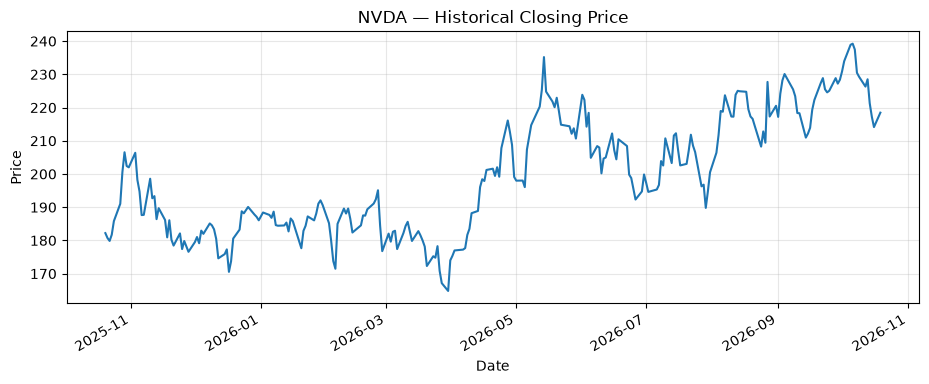

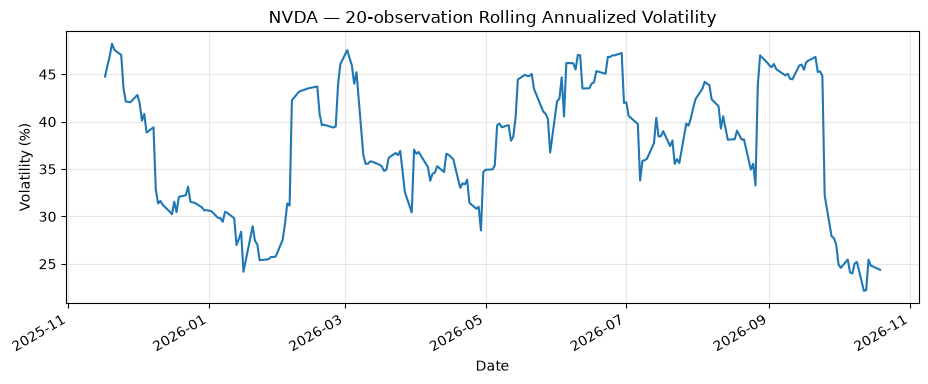

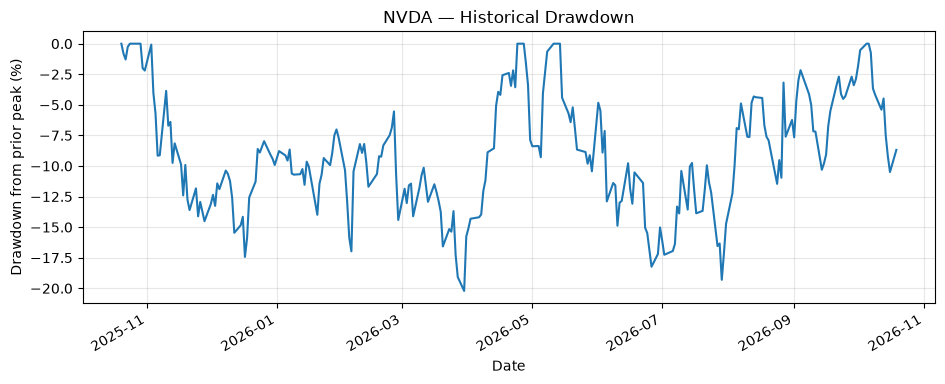

In [12]:
# Plot outputs from the current run so figures stay consistent with the generated report.
if "market" in research and isinstance(research["market"].get("history"), pd.DataFrame):
    hist = research["market"]["history"]
    col = "Adj Close" if "Adj Close" in hist.columns else "Close"
    close = pd.to_numeric(hist[col], errors="coerce").dropna()
    if len(close) >= 2:
        close.plot(figsize=(11, 4), title=f"{research['symbol']} — Historical Closing Price")
        plt.xlabel("Date"); plt.ylabel("Price"); plt.grid(True, alpha=0.3); plt.show()

        daily_returns = close.pct_change().dropna()
        if len(daily_returns) >= 20:
            rolling_vol = daily_returns.rolling(20).std() * np.sqrt(252) * 100
            rolling_vol.plot(figsize=(11, 4), title=f"{research['symbol']} — 20-observation Rolling Annualized Volatility")
            plt.xlabel("Date"); plt.ylabel("Volatility (%)"); plt.grid(True, alpha=0.3); plt.show()

        drawdown = (close / close.cummax() - 1) * 100
        drawdown.plot(figsize=(11, 4), title=f"{research['symbol']} — Historical Drawdown")
        plt.xlabel("Date"); plt.ylabel("Drawdown from prior peak (%)"); plt.grid(True, alpha=0.3); plt.show()
    else:
        print("Price charts unavailable: fewer than two valid closing prices.")
else:
    print("Price chart unavailable; check the market tool trace and errors.")

### How to read the historical price chart

The chart visualizes the closing-price series retrieved for the selected ticker and period. The horizontal axis represents dates and the vertical axis represents the quoted price in the returned data's currency.

Use the chart to observe broad movements and changes in price levels. Do not interpret it as a prediction. The plot does not include a benchmark comparison, risk-adjusted performance, dividends, transaction costs, or a forecast model.

## 14. Workflow trace and memory verification

### Why the trace matters

The plan table shows intended research steps; the tool trace records task status and source counts; the error table records exceptions; the evaluation table shows score/checks/feedback per iteration; optimizer actions show corrective attempts; and memory shows what is persisted for future runs. A successful tool call does not guarantee complete data, so source status and structured validation are shown separately.

In [13]:
print("Planned tasks:")
display(pd.DataFrame(research["plan"]))
print("Tool execution trace:")
display(pd.DataFrame(research.get("tool_trace", [])))
print("Tool errors:")
display(pd.DataFrame(research.get("tool_errors", [])))
print("Evaluation history:")
display(pd.DataFrame([{"iteration": x["iteration"], "score": x["score_out_of_10"],
                       "passed_checks": x["passed_checks"], "total_checks": x["total_checks"],
                       "feedback": "; ".join(x["feedback"])} for x in evaluation_history]))
print("Optimizer actions:")
display(pd.DataFrame(optimizer_actions))
print("Saved memory notes:")
display(pd.DataFrame(memory.retrieve(SYMBOL)))

Planned tasks:


,step,specialist,tool,purpose
0,1,market,history,Analyze historical price and returns
1,2,financial,company_info,Retrieve company profile and key metrics
2,3,financial,statements,Check financial statements
3,4,news,news,Process recent news headlines
4,5,news,news,Recovery retrieval informed by a previous news...


Tool execution trace:


,step,tool,purpose,status,records,source_status
0,1,history,Analyze historical price and returns,completed,NaN,NaN
1,2,company_info,Retrieve company profile and key metrics,completed,NaN,NaN
2,3,statements,Check financial statements,completed,NaN,NaN
3,4,news,Process recent news headlines,completed,0.0,empty
4,5,news,Recovery retrieval informed by a previous news...,completed,0.0,empty


Tool errors:


...

,iteration,score,passed_checks,total_checks,feedback
0,1,9.0,9,10,usable_news_articles_present


Optimizer actions:


""


Saved memory notes:


,timestamp_utc,evaluation_score,period_return_pct,news_count,tool_error_count,brief_note,news_source_status,unresolved_issues,actions_taken
0,2026-10-19T15:52:30.405931+00:00,8.3,20.348966,0,0,# Investment Research Summary: NVDA\nGenerated...,NaN,NaN,NaN
1,2026-10-19T16:11:12.092512+00:00,9.0,20.431278,0,0,# Investment Research Summary: NVDA\nGenerated...,empty,[usable_news_articles_present],[]
2,2026-10-19T16:15:10.784042+00:00,9.0,20.373662,0,0,# Investment Research Summary: NVDA\nGenerated...,empty,[usable_news_articles_present],[]
3,2026-10-19T16:23:15.160812+00:00,9.0,19.904409,0,0,# Investment Research Summary: NVDA\nGenerated...,empty,[usable_news_articles_present],[]


### Interpretation of workflow trace and memory output

Review whether each planned task completed, whether the news source status was `success`, `empty`, `error`, or `partial`, and whether a retry changed the number of usable articles. The latest memory note stores the evaluation score, news status/count, tool-error count, unresolved checks, and actions taken. On a subsequent run, a previous news gap or tool error adds a recovery task to the plan. This is observable rule-based adaptation across runs, not model training.

## 15. Automated tests

The tests below use synthetic inputs and mocked tools where possible, so core logic can be validated without depending on live Yahoo Finance responses.

### Test coverage

The test suite checks planner behavior, memory-informed recovery planning, invalid routing, news-chain stage counts and duplicate handling, known market calculations, structured evaluator behavior, and an optimizer retry using a fake tool. These are unit-style tests; they do not validate live vendor data quality or guarantee the external service will be available.

In [14]:
# Planner and routing tests

# Plan-and-Execute tests: planning is a distinct phase, and execution follows the supplied plan.
planned_symbol, prior_notes, explicit_plan = investment_agent.create_plan("AAPL")
assert planned_symbol == "AAPL"
assert [task["step"] for task in explicit_plan] == list(range(1, len(explicit_plan) + 1))
assert all({"specialist", "tool", "purpose"}.issubset(task) for task in explicit_plan)
assert [x["tool"] for x in planner.plan("AAPL")] == ["history", "company_info", "statements", "news"]
assert planner.plan("AAPL", [{"news_count": 0, "tool_error_count": 0}])[-1]["tool"] == "news"
try:
    router.route({"step": 99, "specialist": "unknown"})
    raise AssertionError("Unknown route should fail")
except ValueError:
    pass

# News prompt-chain tests: stages preserve records and deduplicate repeated headlines.
sample = [
    {"title": "Company reports strong revenue growth", "summary": "Revenue beats estimates by 12%", "publisher": "Example", "link": "https://example.com/1"},
    {"title": "Company reports strong revenue growth", "summary": "Revenue beats estimates by 12%", "publisher": "Example", "link": "https://example.com/1"},
    {"title": "Company faces lawsuit after weak quarter", "summary": "Shares fall 5%", "publisher": "Example", "link": "https://example.com/2"}
]
chain = news_agent.run_chain(sample, "NVDA")
assert chain["stage_counts"]["raw"] == 3
assert chain["stage_counts"]["ingested"] == 2
assert chain["stage_counts"]["extracted"] == 2
assert chain["summary"]["news_count"] == 2
assert chain["summary"]["source_status"] == "success"

# Market metrics tested against a small known series: 100 -> 110 -> 121 = 21% return.
test_history = pd.DataFrame({"Close": [100.0, 110.0, 121.0]})
market_result = MarketAgent().analyze("TEST", test_history)
assert abs(market_result["period_return_pct"] - 21.0) < 1e-8
assert market_result["observations"] == 3

# Evaluator uses structured data checks rather than searching for a literal missing-data phrase.
synthetic_research = {
    "market": {"observations": 3},
    "financial": {"company_summary": {"longName": "Example Inc."}},
    "news": {"summary": {"news_count": 2, "source_status": "success"}},
    "tool_errors": []
}
synthetic_report = "## 1. Company overview\n## 2. Market performance\n## 3. Financial indicators\n## 4. Recent news\n- Source status: success\n## 5. Data quality and limitations\nThis is not individualized financial advice."
assert evaluator.evaluate(synthetic_report, synthetic_research)["score_out_of_10"] == 10.0
assert evaluator.evaluate("# Incomplete", {})["score_out_of_10"] < 8

# Optimizer recovery is exercised with a fake tool; it does not call the network.
class FakeTools:
    def call(self, name, **kwargs):
        assert name == "news"
        return [{"title": "Revenue beats estimates and growth is strong", "publisher": "Test", "link": "https://example.com/news"}]

retry_research = {"symbol": "TEST", "news": news_agent.run_chain([], "TEST"), "tool_errors": []}
retry_eval = {"checks": {"news_status_disclosed": False}}
actions = optimizer.optimize(retry_research, retry_eval, FakeTools(), router)
assert retry_research["news"]["summary"]["news_count"] == 1
assert actions[0]["action"] == "retry_news"
print("All automated unit-style tests passed.")

All automated unit-style tests passed.


### Test results and interpretation

When this cell completes successfully, it verifies that the baseline plan is created, a prior news gap adds a recovery task, unknown routing fails clearly, the prompt chain deduplicates records, market return matches a known test series, structured evaluation can pass a complete synthetic report, and optimizer retry logic can recover a synthetic news record. Live Yahoo Finance behavior remains dependent on network access and vendor responses.

## 16. Evaluation, limitations, and conclusion

### Agent functions and workflows
The notebook implements an explicit Plan-and-Execute agent (separate plan and execution phases), a memory-informed planner, registered tool calls with execution traces, specialist routing, a five-stage news prompt chain, structured evaluation, bounded corrective action, report regeneration, and JSON-backed cross-run notes. The optimizer performs a real news retry when the source is empty or errored; if it cannot improve the result, the limitation remains visible.

### Learning across runs
The memory file stores the prior evaluation score, usable-news count and source status, tool errors, unresolved checks, and actions taken. A subsequent run uses the latest note to add a recovery task after a prior news gap or tool failure. This is transparent rule-based adaptation, not model training.

### Limitations and responsible use
- Yahoo Finance may omit fields, change schemas, rate-limit requests, or return empty data.
- Rule-based news classification remains context-limited even with a simple negation guard.
- Financial ratios require sector and reporting-period context.
- A high quality-check score does not imply that a stock is a good investment.
- The system does not execute trades; human review and independent source verification are required.
- Future improvements could add SEC EDGAR filings, benchmark-relative performance, a validated sentiment model, and human approval gates.

### Conclusion
This project demonstrates all three required workflow patterns and the four requested agent functions with explicit execution evidence. Its strongest evidence is the visible plan/tool trace, intermediate news-chain counts, evaluator feedback, optimizer actions, and memory-informed behavior on later runs.